# Import libraries

In [200]:
import os

import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 50)

import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.feature_selection import mutual_info_regression

# Load data
https://www.kaggle.com/datasets/nicholasjhana/energy-consumption-generation-prices-and-weather

In [201]:
# Define paths to raw data
raw_data_dir = os.path.join("..", "data", "raw")

energy_df = pd.read_csv(os.path.join(raw_data_dir, "energy_dataset.csv"))
weather_df = pd.read_csv(os.path.join(raw_data_dir, "weather_features.csv"))

In [202]:
print("--- Energy Dataset Info ---")
print(energy_df.info())

--- Energy Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   time                                         35064 non-null  str    
 1   generation biomass                           35045 non-null  float64
 2   generation fossil brown coal/lignite         35046 non-null  float64
 3   generation fossil coal-derived gas           35046 non-null  float64
 4   generation fossil gas                        35046 non-null  float64
 5   generation fossil hard coal                  35046 non-null  float64
 6   generation fossil oil                        35045 non-null  float64
 7   generation fossil oil shale                  35046 non-null  float64
 8   generation fossil peat                       35046 non-null  float64
 9   generation geothermal                        35046 non-

In [203]:
print("--- Weather Dataset Info ---")
print(weather_df.info())

--- Weather Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 178396 entries, 0 to 178395
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   dt_iso               178396 non-null  str    
 1   city_name            178396 non-null  str    
 2   temp                 178396 non-null  float64
 3   temp_min             178396 non-null  float64
 4   temp_max             178396 non-null  float64
 5   pressure             178396 non-null  int64  
 6   humidity             178396 non-null  int64  
 7   wind_speed           178396 non-null  int64  
 8   wind_deg             178396 non-null  int64  
 9   rain_1h              178396 non-null  float64
 10  rain_3h              178396 non-null  float64
 11  snow_3h              178396 non-null  float64
 12  clouds_all           178396 non-null  int64  
 13  weather_id           178396 non-null  int64  
 14  weather_main         178396 non-null  str    
 15 

In [204]:
for col in weather_df.select_dtypes(exclude='number'):
    print('='*30)
    print(weather_df[col].value_counts().head(10))

dt_iso
2015-10-01 02:00:00+02:00    10
2016-09-30 02:00:00+02:00    10
2017-09-30 02:00:00+02:00    10
2018-02-28 09:00:00+01:00    10
2018-09-30 02:00:00+02:00    10
2016-01-28 23:00:00+01:00     9
2017-01-27 13:00:00+01:00     9
2017-01-27 14:00:00+01:00     9
2017-02-24 11:00:00+01:00     9
2018-01-07 10:00:00+01:00     9
Name: count, dtype: int64
city_name
Madrid        36267
Bilbao        35951
Seville       35557
 Barcelona    35476
Valencia      35145
Name: count, dtype: int64
weather_main
clear           82685
clouds          68055
rain            17391
mist             3908
fog              2506
drizzle          1724
thunderstorm     1041
haze              435
dust              347
snow              270
Name: count, dtype: int64
weather_description
sky is clear               82685
few clouds                 32101
broken clouds              17448
scattered clouds           15945
light rain                 10905
mist                        3908
moderate rain               3621
o

# Preprocessing

## Data types

In [205]:
# Convert time columns to datetime format
time_col = 'timestamp'
energy_df[time_col] = pd.to_datetime(energy_df['time'], format='ISO8601', utc=True)
weather_df[time_col] = pd.to_datetime(weather_df['dt_iso'], format='ISO8601', utc=True)

# Set time column as index
energy_df = energy_df.set_index(time_col)
weather_df = weather_df.set_index(time_col)

# Drop original time column
energy_df = energy_df.drop(columns=['time'])
weather_df = weather_df.drop(columns=['dt_iso'])

## Resample

In [206]:
# Resample energy data to daily frequency and aggregate by sum
daily_energy = energy_df.resample('D').agg({i: 'sum' for i in energy_df})
print(daily_energy.shape)
daily_energy.head()

(1462, 28)


,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2014-12-31 00:00:00+00:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,0.0,863.0,1051.0,1899.0,0.0,7096.0,43.0,73.0,49.0,196.0,0.0,6378.0,17.0,0.0,6436.0,26118.0,25385.0,50.10,65.41
2015-01-01 00:00:00+00:00,10205.0,5849.0,0.0,100507.0,98387.0,3876.0,0.0,0.0,0.0,0.0,26117.0,25366.0,53977.0,0.0,170338.0,1016.0,1764.0,27448.0,4825.0,0.0,95856.0,25188.0,0.0,94618.0,594078.0,575207.0,1080.76,1490.18
2015-01-02 00:00:00+00:00,9357.0,0.0,0.0,85588.0,30195.0,4820.0,0.0,0.0,0.0,0.0,36260.0,31200.0,89007.0,0.0,170530.0,1095.0,1487.0,30061.0,4478.0,0.0,265441.0,28493.0,0.0,266809.0,660466.0,652525.0,422.36,1666.65
2015-01-03 00:00:00+00:00,10485.0,0.0,0.0,82843.0,33023.0,5515.0,0.0,0.0,0.0,0.0,32666.0,33073.0,93538.0,0.0,170279.0,1876.0,1580.0,27501.0,4856.0,0.0,219294.0,27201.0,0.0,218722.0,612020.0,602346.0,608.21,1565.36
2015-01-04 00:00:00+00:00,9513.0,326.0,0.0,84627.0,55567.0,8559.0,0.0,0.0,0.0,0.0,13765.0,35566.0,77887.0,0.0,166957.0,1969.0,1393.0,57659.0,3819.0,0.0,192387.0,55009.0,0.0,192548.0,652029.0,650518.0,735.80,1413.89


In [207]:
# Resample weather data to daily frequency and aggregate by mean because it has multiple cities per day
daily_weather = weather_df.resample('D').agg({i: 'mean' for i in weather_df.select_dtypes(include='number')})
print(daily_weather.shape)
daily_weather.head()

(1462, 12)


,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id
timestamp,,,,,,,,,,,,
2014-12-31 00:00:00+00:00,272.491463,272.491463,272.491463,1016.400000,82.400000,2.000000,135.200000,0.000,0.0,0.0,0.000000,800.000000
2015-01-01 00:00:00+00:00,277.001207,277.001207,277.001207,1022.125000,75.466667,1.933333,184.866667,0.000,0.0,0.0,0.850000,800.033333
2015-01-02 00:00:00+00:00,277.951217,277.951217,277.951217,1024.691667,77.891667,1.575000,213.858333,0.000,0.0,0.0,6.291667,800.283333
2015-01-03 00:00:00+00:00,278.829727,278.829727,278.829727,1020.375000,78.016667,1.558333,188.366667,0.000,0.0,0.0,1.883333,800.083333
2015-01-04 00:00:00+00:00,279.643354,279.643354,279.643354,1016.008333,77.358333,1.250000,158.775000,0.045,0.0,0.0,11.608333,755.100000


In [208]:
# Most frequent weather conditions
daily_weather_conditions = (
    weather_df[['weather_main']]
    .resample('D')
    .apply(lambda x: x.mode().iloc[0] if not x.empty else np.nan)
)
print(daily_weather_conditions.shape)
daily_weather_conditions.head()

(1462, 1)


,weather_main
timestamp,
2014-12-31 00:00:00+00:00,clear
2015-01-01 00:00:00+00:00,clear
2015-01-02 00:00:00+00:00,clear
2015-01-03 00:00:00+00:00,clear
2015-01-04 00:00:00+00:00,clear


## Merge

In [209]:
# Merge datasets on the time index
merged_df = pd.concat([
    daily_energy,
    daily_weather,
    daily_weather_conditions
], axis=1, join='inner')
print(merged_df.shape)
merged_df.head()

(1462, 41)


,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main
timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2014-12-31 00:00:00+00:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,0.0,863.0,1051.0,1899.0,0.0,7096.0,43.0,73.0,49.0,196.0,0.0,6378.0,17.0,0.0,6436.0,26118.0,25385.0,50.10,65.41,272.491463,272.491463,272.491463,1016.400000,82.400000,2.000000,135.200000,0.000,0.0,0.0,0.000000,800.000000,clear
2015-01-01 00:00:00+00:00,10205.0,5849.0,0.0,100507.0,98387.0,3876.0,0.0,0.0,0.0,0.0,26117.0,25366.0,53977.0,0.0,170338.0,1016.0,1764.0,27448.0,4825.0,0.0,95856.0,25188.0,0.0,94618.0,594078.0,575207.0,1080.76,1490.18,277.001207,277.001207,277.001207,1022.125000,75.466667,1.933333,184.866667,0.000,0.0,0.0,0.850000,800.033333,clear
2015-01-02 00:00:00+00:00,9357.0,0.0,0.0,85588.0,30195.0,4820.0,0.0,0.0,0.0,0.0,36260.0,31200.0,89007.0,0.0,170530.0,1095.0,1487.0,30061.0,4478.0,0.0,265441.0,28493.0,0.0,266809.0,660466.0,652525.0,422.36,1666.65,277.951217,277.951217,277.951217,1024.691667,77.891667,1.575000,213.858333,0.000,0.0,0.0,6.291667,800.283333,clear
2015-01-03 00:00:00+00:00,10485.0,0.0,0.0,82843.0,33023.0,5515.0,0.0,0.0,0.0,0.0,32666.0,33073.0,93538.0,0.0,170279.0,1876.0,1580.0,27501.0,4856.0,0.0,219294.0,27201.0,0.0,218722.0,612020.0,602346.0,608.21,1565.36,278.829727,278.829727,278.829727,1020.375000,78.016667,1.558333,188.366667,0.000,0.0,0.0,1.883333,800.083333,clear
2015-01-04 00:00:00+00:00,9513.0,326.0,0.0,84627.0,55567.0,8559.0,0.0,0.0,0.0,0.0,13765.0,35566.0,77887.0,0.0,166957.0,1969.0,1393.0,57659.0,3819.0,0.0,192387.0,55009.0,0.0,192548.0,652029.0,650518.0,735.80,1413.89,279.643354,279.643354,279.643354,1016.008333,77.358333,1.250000,158.775000,0.045,0.0,0.0,11.608333,755.100000,clear


In [210]:
# Check for missing values
merged_df.isna().sum().where(lambda x: x > 0).dropna().astype(int).sort_values(ascending=False)

Series([], dtype: int64)

## One-hot encoding

In [211]:
weather_main_encoded = pd.get_dummies(merged_df['weather_main'], prefix='weather_main', dtype=int)
merged_df = pd.concat([merged_df, weather_main_encoded], axis=1).drop(columns=['weather_main'])
print(merged_df.shape)
merged_df.head()

(1462, 43)


,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main_clear,weather_main_clouds,weather_main_rain
timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2014-12-31 00:00:00+00:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,0.0,863.0,1051.0,1899.0,0.0,7096.0,43.0,73.0,49.0,196.0,0.0,6378.0,17.0,0.0,6436.0,26118.0,25385.0,50.10,65.41,272.491463,272.491463,272.491463,1016.400000,82.400000,2.000000,135.200000,0.000,0.0,0.0,0.000000,800.000000,1,0,0
2015-01-01 00:00:00+00:00,10205.0,5849.0,0.0,100507.0,98387.0,3876.0,0.0,0.0,0.0,0.0,26117.0,25366.0,53977.0,0.0,170338.0,1016.0,1764.0,27448.0,4825.0,0.0,95856.0,25188.0,0.0,94618.0,594078.0,575207.0,1080.76,1490.18,277.001207,277.001207,277.001207,1022.125000,75.466667,1.933333,184.866667,0.000,0.0,0.0,0.850000,800.033333,1,0,0
2015-01-02 00:00:00+00:00,9357.0,0.0,0.0,85588.0,30195.0,4820.0,0.0,0.0,0.0,0.0,36260.0,31200.0,89007.0,0.0,170530.0,1095.0,1487.0,30061.0,4478.0,0.0,265441.0,28493.0,0.0,266809.0,660466.0,652525.0,422.36,1666.65,277.951217,277.951217,277.951217,1024.691667,77.891667,1.575000,213.858333,0.000,0.0,0.0,6.291667,800.283333,1,0,0
2015-01-03 00:00:00+00:00,10485.0,0.0,0.0,82843.0,33023.0,5515.0,0.0,0.0,0.0,0.0,32666.0,33073.0,93538.0,0.0,170279.0,1876.0,1580.0,27501.0,4856.0,0.0,219294.0,27201.0,0.0,218722.0,612020.0,602346.0,608.21,1565.36,278.829727,278.829727,278.829727,1020.375000,78.016667,1.558333,188.366667,0.000,0.0,0.0,1.883333,800.083333,1,0,0
2015-01-04 00:00:00+00:00,9513.0,326.0,0.0,84627.0,55567.0,8559.0,0.0,0.0,0.0,0.0,13765.0,35566.0,77887.0,0.0,166957.0,1969.0,1393.0,57659.0,3819.0,0.0,192387.0,55009.0,0.0,192548.0,652029.0,650518.0,735.80,1413.89,279.643354,279.643354,279.643354,1016.008333,77.358333,1.250000,158.775000,0.045,0.0,0.0,11.608333,755.100000,1,0,0


## Remove data leakage columns

In [212]:
# Data leakage columns to remove
remove_cols = [i for i in merged_df if 'generation' in i or 'forecast' in i]
remove_cols += ['price actual', 'price day ahead', 'total load forecast']

print("# of columns to remove: ", len(remove_cols))
print(*remove_cols, sep="\n")

# of columns to remove:  28
generation biomass
generation fossil brown coal/lignite
generation fossil coal-derived gas
generation fossil gas
generation fossil hard coal
generation fossil oil
generation fossil oil shale
generation fossil peat
generation geothermal
generation hydro pumped storage aggregated
generation hydro pumped storage consumption
generation hydro run-of-river and poundage
generation hydro water reservoir
generation marine
generation nuclear
generation other
generation other renewable
generation solar
generation waste
generation wind offshore
generation wind onshore
forecast solar day ahead
forecast wind offshore eday ahead
forecast wind onshore day ahead
total load forecast
price actual
price day ahead
total load forecast


In [213]:
merged_df = merged_df.drop(columns=remove_cols)
merged_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1462 entries, 2014-12-31 00:00:00+00:00 to 2018-12-31 00:00:00+00:00
Freq: D
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   total load actual    1462 non-null   float64
 1   temp                 1462 non-null   float64
 2   temp_min             1462 non-null   float64
 3   temp_max             1462 non-null   float64
 4   pressure             1462 non-null   float64
 5   humidity             1462 non-null   float64
 6   wind_speed           1462 non-null   float64
 7   wind_deg             1462 non-null   float64
 8   rain_1h              1462 non-null   float64
 9   rain_3h              1462 non-null   float64
 10  snow_3h              1462 non-null   float64
 11  clouds_all           1462 non-null   float64
 12  weather_id           1462 non-null   float64
 13  weather_main_clear   1462 non-null   int64  
 14  weather_main_clouds  1462 non-null   int64 

## Lag features

In [214]:
# Lag the target variable to capture weekly seasonality
target_col = 'total load actual'
merged_df[f'{target_col}_lag_1d'] = merged_df[target_col].shift(1)
merged_df[f'{target_col}_lag_2d'] = merged_df[target_col].shift(2)
merged_df[f'{target_col}_lag_7d'] = merged_df[target_col].shift(7)

In [215]:
# Lag the core weather features: temperature and humidity
weather_metrics_to_lag = ['temp', 'humidity']
for col in weather_metrics_to_lag:
    merged_df[f'{col}_lag_1d'] = merged_df[col].shift(1)
    merged_df[f'{col}_lag_2d'] = merged_df[col].shift(2)

In [216]:
# Drop the first 7 rows with NaN values due to lagging
merged_df = merged_df.dropna()
print(merged_df.shape)
merged_df.info()

(1455, 23)
<class 'pandas.DataFrame'>
DatetimeIndex: 1455 entries, 2015-01-07 00:00:00+00:00 to 2018-12-31 00:00:00+00:00
Freq: D
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   total load actual         1455 non-null   float64
 1   temp                      1455 non-null   float64
 2   temp_min                  1455 non-null   float64
 3   temp_max                  1455 non-null   float64
 4   pressure                  1455 non-null   float64
 5   humidity                  1455 non-null   float64
 6   wind_speed                1455 non-null   float64
 7   wind_deg                  1455 non-null   float64
 8   rain_1h                   1455 non-null   float64
 9   rain_3h                   1455 non-null   float64
 10  snow_3h                   1455 non-null   float64
 11  clouds_all                1455 non-null   float64
 12  weather_id                1455 non-null   float64
 13  weather

# Decomposition

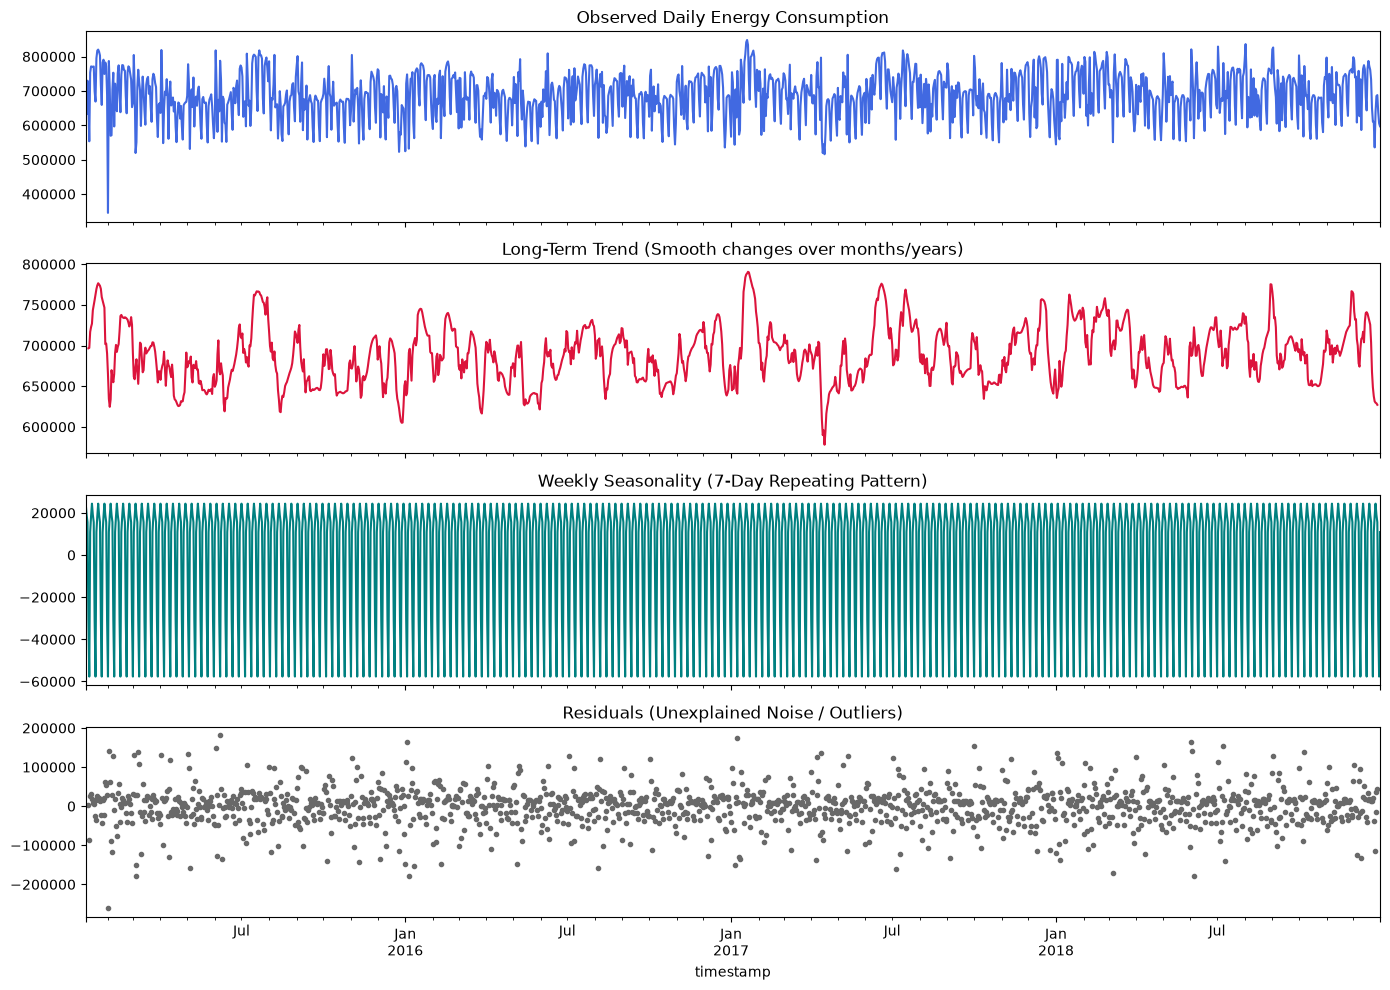

In [217]:
# Seasonal decomposition of 'total load actual' with a period of 7 (weekly cycle)
decomposition = seasonal_decompose(merged_df[target_col], model='additive', period=7)

# Plot the decomposition results
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, sharex=True, figsize=(14, 10))

decomposition.observed.plot(ax=ax1, color='royalblue')
ax1.set_title('Observed Daily Energy Consumption')

decomposition.trend.plot(ax=ax2, color='crimson')
ax2.set_title('Long-Term Trend (Smooth changes over months/years)')

decomposition.seasonal.plot(ax=ax3, color='teal')
ax3.set_title('Weekly Seasonality (7-Day Repeating Pattern)')

decomposition.resid.plot(ax=ax4, color='dimgray', style='.')
ax4.set_title('Residuals (Unexplained Noise / Outliers)')

plt.tight_layout()
plt.show()

## Findings from decomposition
* **Observed Daily Energy Consumption:** The overall series shows a remarkably stable average baseline, hovering around 600,000 to 700,000 units with high-frequency oscillations. There are a few noticeable sharp downward spikes (outliers), which often correspond to major national holidays or grid maintenance events.
* **Long-Term Trend:** Stripping out the weekly fluctuations reveals a clear macro-seasonal pattern. Notice the recurring wave-like peaks and valleys every single year. You can spot a double-peak behavior annually—one major surge in winter (heating demand) and another in summer (cooling/AC demand), with valleys in spring and autumn.
* **Weekly Seasonality:** The dense, repeating teal pattern confirms a dominant 7-day cyclical rhythm. The swing ranges from +20,000 units at peak weekday utilization down to nearly -60,000 units on the lowest utilization days. This indicates that human operational cycles (weekdays vs. weekends) drastically dictate consumption baselines.
* **Residuals:** The remaining noise is centered tightly around zero, which indicates your additive assumption is correct. The scatter remains consistently bounded between roughly -100,000 and +100,000 units across the multi-year span, showing stable variance over time.

# Temperature vs energy demand

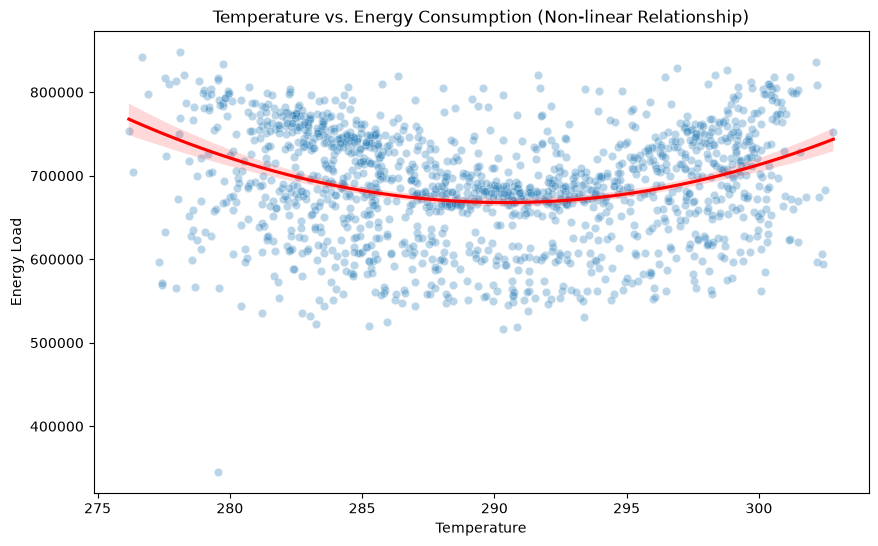

In [218]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=merged_df, x='temp', y=target_col, alpha=0.3)
sns.regplot(data=merged_df, x='temp', y=target_col, scatter=False, color="red", order=2)
plt.title("Temperature vs. Energy Consumption (Non-linear Relationship)")
plt.xlabel("Temperature")
plt.ylabel("Energy Load")
plt.show()

# Mutual information

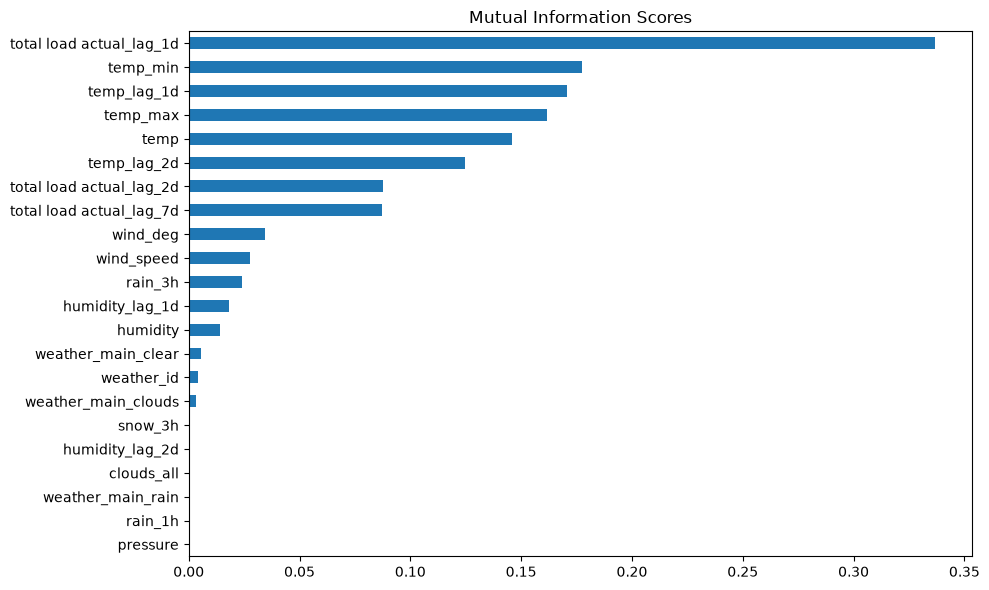

In [219]:
X = merged_df.drop(columns=[target_col])
y = merged_df[target_col]

mi_scores = mutual_info_regression(X, y, random_state=42)
mi_scores = pd.Series(mi_scores, index=X.columns)

mi_scores.sort_values().plot(kind='barh', figsize=(10, 6), title='Mutual Information Scores')
plt.tight_layout()
plt.show()

In [221]:
mi_scores.sort_values(ascending=False)

total load actual_lag_1d    0.336787
temp_min                    0.177496
temp_lag_1d                 0.170578
temp_max                    0.161700
temp                        0.145643
temp_lag_2d                 0.124533
total load actual_lag_2d    0.087829
total load actual_lag_7d    0.087078
wind_deg                    0.034607
wind_speed                  0.027450
rain_3h                     0.023887
humidity_lag_1d             0.018037
humidity                    0.014326
weather_main_clear          0.005577
weather_id                  0.004022
weather_main_clouds         0.003174
snow_3h                     0.000507
pressure                    0.000000
clouds_all                  0.000000
rain_1h                     0.000000
weather_main_rain           0.000000
humidity_lag_2d             0.000000
dtype: float64